In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

from collections import defaultdict

# Reproducibility
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

print("Reinforcement Learning Module III")
print("Libraries imported successfully.")

Reinforcement Learning Module III
Libraries imported successfully.


In [2]:
# Environment:
# S1 -> S2 -> S3 -> Terminal

states = ["S1", "S2", "S3"]
rewards = [2, 4, 8]

gamma = 0.9

def generate_episode():
    episode = []

    for i in range(len(states)):
        episode.append((states[i], rewards[i]))

    return episode


episodes = [generate_episode() for _ in range(10)]

print("Generated Episodes:")

for i, episode in enumerate(episodes, 1):
    print(f"Episode {i}: {episode}")

Generated Episodes:
Episode 1: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 2: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 3: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 4: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 5: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 6: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 7: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 8: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 9: [('S1', 2), ('S2', 4), ('S3', 8)]
Episode 10: [('S1', 2), ('S2', 4), ('S3', 8)]


In [3]:
def first_visit_mc(episodes, gamma):

    returns = defaultdict(list)

    for episode in episodes:

        G = 0
        episode_returns = []

        for state, reward in reversed(episode):

            G = reward + gamma * G
            episode_returns.insert(0, G)

        visited = set()

        for (state, reward), G in zip(episode, episode_returns):

            if state not in visited:

                returns[state].append(G)
                visited.add(state)

    values = {}

    for state in states:

        values[state] = np.mean(returns[state])

    return values


mc_values = first_visit_mc(episodes, gamma)

print("\nFirst-Visit Monte Carlo Values")

for state, value in mc_values.items():

    print(f"{state}: {value:.4f}")


First-Visit Monte Carlo Values
S1: 12.0800
S2: 11.2000
S3: 8.0000


In [4]:
# Episode:
# S1 -> S2 -> S3 -> S2 -> Terminal

episode = [
    ("S1", 2),
    ("S2", 4),
    ("S3", 3),
    ("S2", 6)
]

gamma = 1.0

def calculate_returns(episode, gamma):

    G = 0
    returns = []

    for state, reward in reversed(episode):

        G = reward + gamma * G
        returns.insert(0, G)

    return returns


returns = calculate_returns(episode, gamma)

print("Returns:", returns)

s2_returns = []

for (state, reward), G in zip(episode, returns):

    if state == "S2":

        s2_returns.append(G)


first_visit = s2_returns[0]
every_visit = np.mean(s2_returns)

print("\nMonte Carlo Comparison")

print("First-Visit V(S2):", first_visit)
print("Every-Visit V(S2):", every_visit)

Returns: [15.0, 13.0, 9.0, 6.0]

Monte Carlo Comparison
First-Visit V(S2): 13.0
Every-Visit V(S2): 9.5


In [5]:
returns = [10, 6, 14, 8]

V = 0
results = []

for episode, G in enumerate(returns, 1):

    old_value = V

    V = V + (G - V) / episode

    results.append({
        "Episode": episode,
        "Return": G,
        "Old Value": old_value,
        "New Value": V
    })


df = pd.DataFrame(results)

display(df)

print("Final Incremental Value:", V)

print("Ordinary Average:", np.mean(returns))

,Episode,Return,Old Value,New Value
0,1,10,0.0,10.0
1,2,6,10.0,8.0
2,3,14,8.0,10.0
3,4,8,10.0,9.5


Final Incremental Value: 9.5
Ordinary Average: 9.5


In [6]:
states = ["S1", "S2", "S3"]

rewards = [2, 4, 8]

alpha = 0.1
gamma = 0.9

V = {
    state: 0.0 for state in states
}

history = []

for episode in range(1, 101):

    for i, state in enumerate(states):

        reward = rewards[i]

        if i == len(states) - 1:

            next_value = 0

        else:

            next_state = states[i + 1]

            next_value = V[next_state]

        td_target = reward + gamma * next_value

        td_error = td_target - V[state]

        V[state] += alpha * td_error

    history.append({
        "Episode": episode,
        "V(S1)": V["S1"],
        "V(S2)": V["S2"],
        "V(S3)": V["S3"]
    })


td_df = pd.DataFrame(history)

display(td_df.tail(10))

print("\nFinal TD(0) Values")

for state, value in V.items():

    print(state, round(value, 4))

,Episode,V(S1),V(S2),V(S3)
90,91,12.049724,11.194241,7.999452
91,92,12.052233,11.194768,7.999506
92,93,12.054539,11.195246,7.999556
93,94,12.056657,11.195682,7.999600
94,95,12.058603,11.196078,7.999640
95,96,12.060390,11.196437,7.999676
96,97,12.062030,11.196765,7.999709
97,98,12.063536,11.197062,7.999738
98,99,12.064918,11.197332,7.999764
99,100,12.066186,11.197578,7.999788



Final TD(0) Values
S1 12.0662
S2 11.1976
S3 7.9998


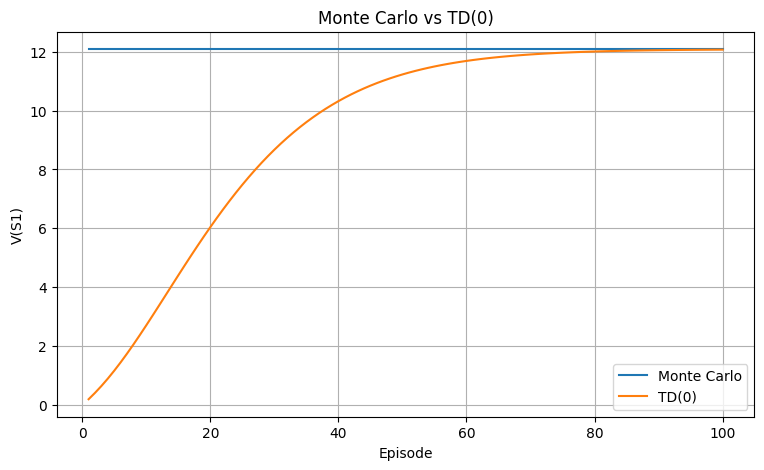

In [7]:
def compare_mc_td(episodes=100):

    V_mc = {s: 0.0 for s in states}
    V_td = {s: 0.0 for s in states}

    counts = defaultdict(int)

    results = []

    for ep in range(1, episodes + 1):

        episode = generate_episode()

        returns = calculate_returns(episode, gamma=0.9)

        # Monte Carlo update

        for (state, reward), G in zip(episode, returns):

            counts[state] += 1

            V_mc[state] += (
                G - V_mc[state]
            ) / counts[state]

        # TD(0) update

        for i, state in enumerate(states):

            reward = rewards[i]

            next_value = (
                V_td[states[i + 1]]
                if i < 2 else 0
            )

            target = reward + 0.9 * next_value

            V_td[state] += 0.1 * (
                target - V_td[state]
            )

        results.append({
            "Episode": ep,
            "MC": V_mc["S1"],
            "TD": V_td["S1"]
        })

    return pd.DataFrame(results)


comparison = compare_mc_td()

plt.plot(
    comparison["Episode"],
    comparison["MC"],
    label="Monte Carlo"
)

plt.plot(
    comparison["Episode"],
    comparison["TD"],
    label="TD(0)"
)

plt.xlabel("Episode")
plt.ylabel("V(S1)")

plt.title("Monte Carlo vs TD(0)")

plt.legend()
plt.show()

In [8]:
GRID_SIZE = 4

START = (0, 0)
GOAL = (3, 3)

ACTIONS = {
    0: (-1, 0),
    1: (1, 0),
    2: (0, -1),
    3: (0, 1)
}

ACTION_SYMBOLS = {
    0: "↑",
    1: "↓",
    2: "←",
    3: "→"
}

def grid_step(state, action):

    dr, dc = ACTIONS[action]

    r = np.clip(state[0] + dr, 0, 3)
    c = np.clip(state[1] + dc, 0, 3)

    next_state = (int(r), int(c))

    done = next_state == GOAL

    reward = 10 if done else -1

    return next_state, reward, done


def epsilon_greedy(Q, state, epsilon):

    if random.random() < epsilon:

        return random.choice(list(ACTIONS.keys()))

    return int(np.argmax(Q[state]))

In [9]:
def train_sarsa(episodes=500):

    Q = defaultdict(lambda: np.zeros(4))

    alpha = 0.15
    gamma = 0.95
    epsilon = 0.15

    rewards_history = []
    steps_history = []

    for episode in range(episodes):

        state = START

        action = epsilon_greedy(Q, state, epsilon)

        total_reward = 0
        steps = 0
        done = False

        while not done and steps < 100:

            next_state, reward, done = grid_step(
                state, action
            )

            if not done:

                next_action = epsilon_greedy(
                    Q, next_state, epsilon
                )

                target = (
                    reward + gamma *
                    Q[next_state][next_action]
                )

            else:

                next_action = None
                target = reward

            td_error = target - Q[state][action]

            Q[state][action] += alpha * td_error

            state = next_state

            if next_action is not None:
                action = next_action

            total_reward += reward
            steps += 1

        rewards_history.append(total_reward)
        steps_history.append(steps)

    return Q, rewards_history, steps_history


Q_sarsa, sarsa_rewards, sarsa_steps = train_sarsa()

print("SARSA Training Completed")
print("Average Reward:", np.mean(sarsa_rewards[-100:]))
print("Average Steps:", np.mean(sarsa_steps[-100:]))

SARSA Training Completed
Average Reward: 4.19
Average Steps: 6.81


In [10]:
def display_policy(Q):

    policy = []

    for r in range(4):

        row = []

        for c in range(4):

            state = (r, c)

            if state == GOAL:

                row.append("G")

            else:

                action = np.argmax(Q[state])

                row.append(ACTION_SYMBOLS[action])

        policy.append(row)

    display(pd.DataFrame(policy))


display_policy(Q_sarsa)

,0,1,2,3
0,↓,→,↓,↓
1,→,↓,↓,↓
2,→,→,↓,↓
3,→,→,→,G


In [11]:
def train_q_learning(episodes=500):

    Q = defaultdict(lambda: np.zeros(4))

    alpha = 0.15
    gamma = 0.95
    epsilon = 0.15

    rewards_history = []
    steps_history = []

    for episode in range(episodes):

        state = START

        total_reward = 0
        steps = 0
        done = False

        while not done and steps < 100:

            action = epsilon_greedy(
                Q, state, epsilon
            )

            next_state, reward, done = grid_step(
                state, action
            )

            if done:

                target = reward

            else:

                target = reward + gamma * np.max(
                    Q[next_state]
                )

            td_error = target - Q[state][action]

            Q[state][action] += alpha * td_error

            state = next_state

            total_reward += reward
            steps += 1

        rewards_history.append(total_reward)
        steps_history.append(steps)

    return Q, rewards_history, steps_history


Q_qlearning, q_rewards, q_steps = train_q_learning()

print("Q-Learning Completed")

print("Average Reward:", np.mean(q_rewards[-100:]))

print("Average Steps:", np.mean(q_steps[-100:]))

Q-Learning Completed
Average Reward: 3.85
Average Steps: 7.15


In [12]:
print("Final Q-Learning Q-Table")

for r in range(4):

    for c in range(4):

        state = (r, c)

        print(
            state,
            np.round(Q_qlearning[state], 3)
        )


print("\nFinal Policy")

display_policy(Q_qlearning)

Final Q-Learning Q-Table
(0, 0) [1.97  3.09  1.976 3.213]
(0, 1) [3.033 4.435 1.702 3.68 ]
(0, 2) [ 0.9    5.707 -0.255  0.039]
(0, 3) [ 0.231  6.673 -0.011  0.231]
(1, 0) [ 0.077 -1.412 -0.24   4.433]
(1, 1) [3.023 4.398 3.037 5.721]
(1, 2) [4.085 6.426 4.253 7.075]
(1, 3) [4.221 8.5   5.397 6.045]
(2, 0) [-1.049 -0.969 -1.027 -0.89 ]
(2, 1) [-0.617 -0.533 -0.637  6.752]
(2, 2) [2.293 3.045 0.122 8.499]
(2, 3) [ 6.676 10.     6.85   8.379]
(3, 0) [-0.614 -0.593 -0.593 -0.392]
(3, 1) [-0.449 -0.407 -0.299  1.771]
(3, 2) [-0.15  -0.15  -0.15   8.327]
(3, 3) [0. 0. 0. 0.]

Final Policy


,0,1,2,3
0,→,↓,↓,↓
1,→,→,→,↓
2,→,→,→,↓
3,→,→,→,G


,Algorithm,Average Reward,Average Steps,Episodes
0,SARSA,4.19,6.81,500
1,Q-Learning,3.85,7.15,500


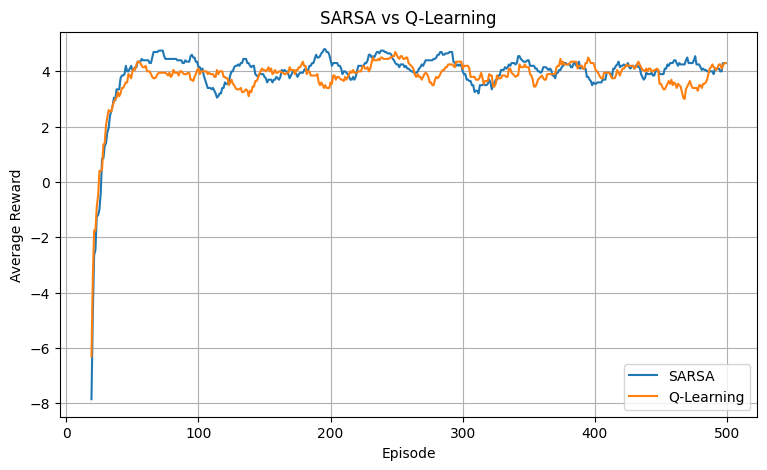

In [14]:
comparison_df = pd.DataFrame({

    "Algorithm": ["SARSA", "Q-Learning"],

    "Average Reward": [
        np.mean(sarsa_rewards[-100:]),
        np.mean(q_rewards[-100:])
    ],

    "Average Steps": [
        np.mean(sarsa_steps[-100:]),
        np.mean(q_steps[-100:])
    ],

    "Episodes": [500, 500]

})

display(comparison_df)


plt.plot(
    pd.Series(sarsa_rewards).rolling(20).mean(),
    label="SARSA"
)

plt.plot(
    pd.Series(q_rewards).rolling(20).mean(),
    label="Q-Learning"
)

plt.xlabel("Episode")
plt.ylabel("Average Reward")

plt.title("SARSA vs Q-Learning")

plt.legend()
plt.show()